# EDA - Online Retail II

## Pyetjet
1. Kush janë klientët më të vlefshëm dhe sa e përqendruar është shitja te ata?
2. Cilat grupe klientësh ekzistojnë sipas sjelljes së blerjes (RFM)?
3. Cilët klientë janë në rrezik humbjeje?
4. Sa do të shesë dyqani në ditët e ardhshme?
5. Cilat veçori ndikojnë më shumë në shitjet ditore?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format","{:,.2f}".format)

In [2]:
df = pd.read_csv("../data/raw/online_retail_II.csv", parse_dates=["InvoiceDate"], low_memory=False)
print(df.shape)
df.head()

(1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 65.1 MB


In [4]:
df.describe()

,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394029,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


In [5]:
pd.DataFrame({
    "missing": df.isna().sum(),
    "pct": (df.isna().mean()*100).round(2)
})

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [8]:
print("Fatura unike: ", df["Invoice"].nunique())
print("Klient unik: ", df["Customer ID"].nunique())
print("Produkte unike: ", df["StockCode"].nunique())
print("Vende: ", df["Country"].nunique())
print("Periudha: ", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())

Fatura unike:  53628
Klient unik:  5942
Produkte unike:  5305
Vende:  43
Periudha:  2009-12-01 07:45:00 -> 2011-12-09 12:50:00


In [9]:
print(df["Country"].value_counts().head(10))
print("Rreshta kthimesh (fatura me C): ", df["Invoice"].astype(str).str.startswith("C").sum())

Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64
Rreshta kthimesh (fatura me C):  19494


## Vëzhgimet e Ditës 1

- Dataseti ka **1,067,371 rreshta** dhe **8 kolona**, i bashkuar nga dy fletë Excel (2009–2010: 525,461 rreshta; 2010–2011: 541,910 rreshta).
- Të dhënat mbulojnë periudhën nga dhjetori 2009 deri në dhjetor 2011 (datat e sakta: 2009-12-01 deri më 2011-12-09).
- Një faturë përmban disa rreshta, sepse çdo rresht është një produkt brenda një fature. Ka 53628 fatura unike, 5942 klientë unikë dhe 5305 produkte unike.
- **Customer ID mungon në 22.77% të rreshtave.** Këta rreshta nuk mund të përdoren në analizën e klientëve, por mbeten të vlefshëm për shitjet totale.
- `Quantity` dhe `Price` kanë vlera negative (minimumi i `Quantity` është -80995, ai i `Price` është -53,594.36). Të paktën një pjesë e tyre lidhen me fatura anuluese (numri i faturës fillon me "C"), dhe ka 19494 rreshta të tillë.
- Vendi me më shumë rreshta është **United Kingdom**, me 91.9% të të gjithë rreshtave.

## Dita 2: Kontrolli i cilësisë së të dhënave

In [5]:
dups = df.duplicated().sum()
print("Rreshta te duplikuar: ", dups,f"({dups / len(df)*100:.2f}%)")

Rreshta te duplikuar:  34335 (3.22%)


In [6]:
df["Invoice"] = df["Invoice"].astype(str)
cancel = df["Invoice"].str.startswith("C")

print("Rreshta anulimesh (fatura me C): ", cancel.sum())
print("Rreshta me Quantity < 0: ",(df["Quantity"] < 0).sum())
print("Quantity < 0 por pa C ne fature: ", ((df["Quantity"] < 0) & ~cancel).sum())

Rreshta anulimesh (fatura me C):  19494
Rreshta me Quantity < 0:  22950
Quantity < 0 por pa C ne fature:  3457


In [7]:
df[(df["Quantity"]<0) & ~cancel].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.00,NaN,United Kingdom
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.00,NaN,United Kingdom
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.00,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,2009-12-02 13:23:00,0.00,NaN,United Kingdom
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.00,NaN,United Kingdom


In [10]:
df[(df["Quantity"]<0) & cancel].head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,"16,321.00",Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,"16,321.00",Australia
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,"16,321.00",Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,"16,321.00",Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,"16,321.00",Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,"16,321.00",Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,"17,592.00",United Kingdom


In [13]:
print("Price == 0:", (df["Price"]==0).sum())
print("Price < 0:", (df["Price"]<0).sum())
df[df["Price"] <= 0].head(5)

Price == 0: 6202
Price < 0: 5


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.00,NaN,United Kingdom
283,489463,71477,short,-240,2009-12-01 10:52:00,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.00,NaN,United Kingdom


In [19]:
codes = df["StockCode"].astype(str)
non_product = codes[~codes.str.match(r"^\d{5}")].value_counts()
print(non_product.sum())
print(non_product.head(20))

6093
StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
DCGS0076          15
TEST001           15
DCGS0003          14
Name: count, dtype: int64


In [15]:
df["Revenue"] = df["Quantity"] * df["Price"]
no_id = df["Customer ID"].isna()
print("Rreshta pa Customer ID:", no_id.sum())
print("Pjesa e te ardhurave pa Customer ID (%):", 
        round(df.loc[no_id, "Revenue"].sum() / df["Revenue"].sum()*100,1))
print("Description qe mungun: ", df["Description"].isna().sum())

Rreshta pa Customer ID: 243007
Pjesa e te ardhurave pa Customer ID (%): 13.7
Description qe mungun:  4382


In [16]:
print(df["Quantity"].quantile([0.5,0.9,0.99,0.999]))
print(df["Price"].quantile([0.5, 0.9, 0.99, 0.999]))
df.nlargest(5, "Quantity")

0.50     3.00
0.90    24.00
0.99   100.00
1.00   500.00
Name: Quantity, dtype: float64
0.50     2.10
0.90     7.95
0.99    18.00
1.00   217.02
Name: Price, dtype: float64


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,"16,446.00",United Kingdom,"168,469.60"
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,"12,346.00",United Kingdom,"77,183.60"
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,"13,902.00",Denmark,"1,915.20"
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,"13,902.00",Denmark,"1,296.00"
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,"13,902.00",Denmark,"1,296.00"


### Përmbledhja e problemeve

| Problemi | Rreshta | % | Vendimi i planifikuar |
|---|---|---|---|
| Rreshta të dublikuar | 34335 | 3.22% | Hiqen |
| Anulime (fatura me C) | 19494 | 1.83% | Ndahen nga shitjet dhe trajtohen veçmas |
| Sasi negative pa C | 3457 | 0.32% | Hiqen nga shitjet |
| Price = 0 ose negativ | 6207 (6202 + 5) | 0.58% | Hiqen |
| Kode jo-produkte (POST, D, M, ...) | 6093 | 0.57% | Shqyrtohen, pastaj hiqen |
| Customer ID që mungon | 243007 | 22.77% | Hiqen nga analiza e klientëve, mbahen për shitjet totale |

## EDA univariate

In [3]:
df["Invoice"] = df["Invoice"].astype(str)
df["Revenue"] = df["Quantity"] * df["Price"]

sales = df[(df["Quantity"] > 0 ) & (df["Price"] > 0) & (~df["Invoice"].str.startswith("C"))].copy()
print("Rreshta shitjesh: ", len(sales), f"({len(sales) / len(df) * 100:.1f}% e te gjitheve)")

Rreshta shitjesh:  1041670 (97.6% e te gjitheve)


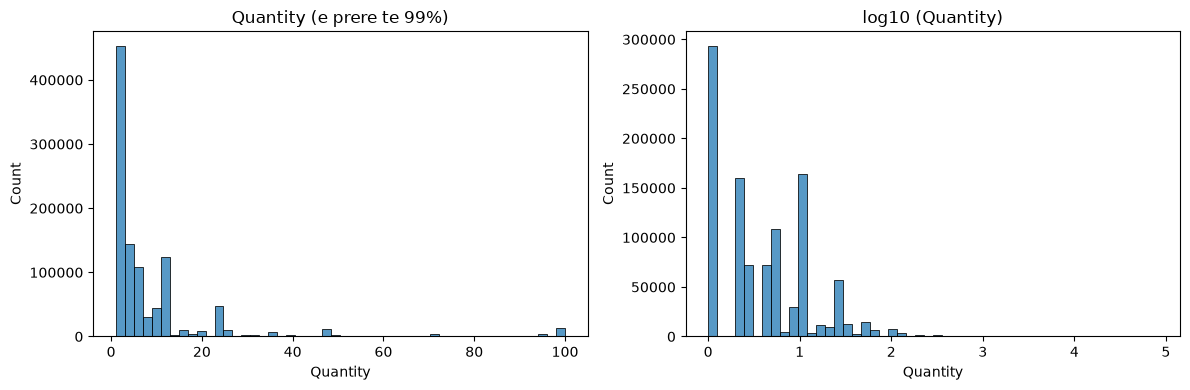

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sales["Quantity"].clip(upper=sales["Quantity"].quantile(0.99)), bins=50, ax=axes[0])
axes[0].set_title("Quantity (e prere te 99%)")
sns.histplot(np.log10(sales["Quantity"]), bins=50, ax=axes[1])
axes[1].set_title("log10 (Quantity)")
plt.tight_layout()
plt.show()

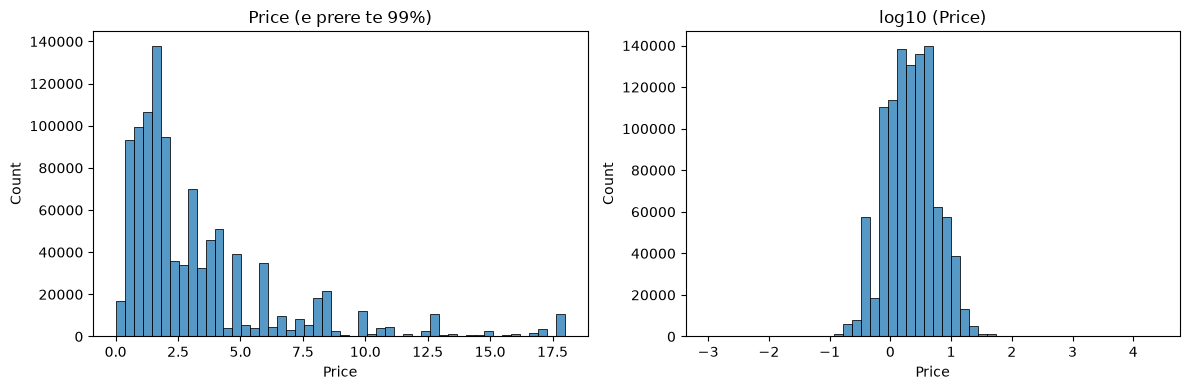

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(sales["Price"].clip(upper=sales["Price"].quantile(0.99)), bins=50, ax=axes[0])
axes[0].set_title("Price (e prere te 99%)")
sns.histplot(np.log10(sales["Price"]), bins=50, ax=axes[1])
axes[1].set_title("log10 (Price)")
plt.tight_layout()
plt.show()

count   1,041,670.00
mean           20.13
std           203.12
min             0.00
25%             3.90
50%             9.96
75%            17.70
max       168,469.60
Name: Revenue, dtype: float64


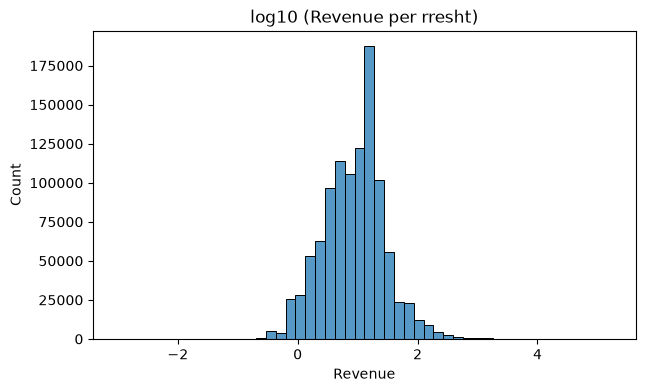

In [7]:
print(sales["Revenue"].describe())

plt.figure(figsize=(7, 4))
sns.histplot(np.log10(sales["Revenue"]), bins=50)
plt.title("log10 (Revenue per rresht)")
plt.show()

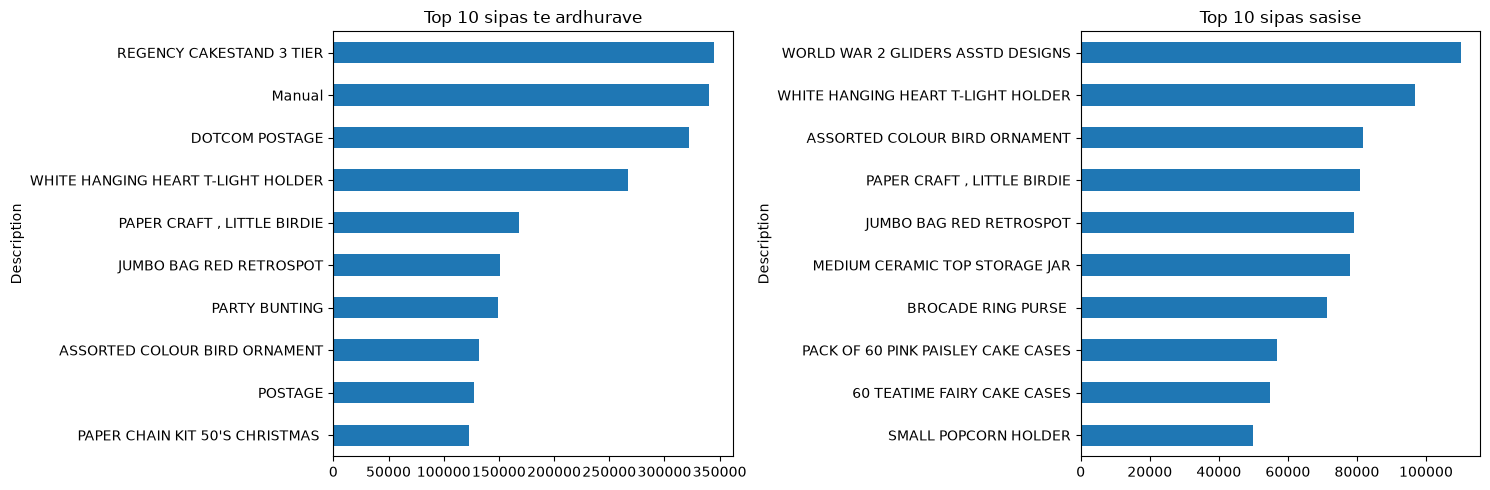

In [8]:
top_rev = sales.groupby("Description")["Revenue"].sum().nlargest(10)
top_qty = sales.groupby("Description")["Quantity"].sum().nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_rev.sort_values().plot.barh(ax=axes[0], title="Top 10 sipas te ardhurave")
top_qty.sort_values().plot.barh(ax=axes[1], title="Top 10 sipas sasise")
plt.tight_layout()
plt.show()

Country
United Kingdom   85.20
EIRE              3.20
Netherlands       2.60
Germany           2.10
France            1.70
Australia         0.80
Spain             0.50
Switzerland       0.50
Sweden            0.40
Denmark           0.30
Name: Revenue, dtype: float64


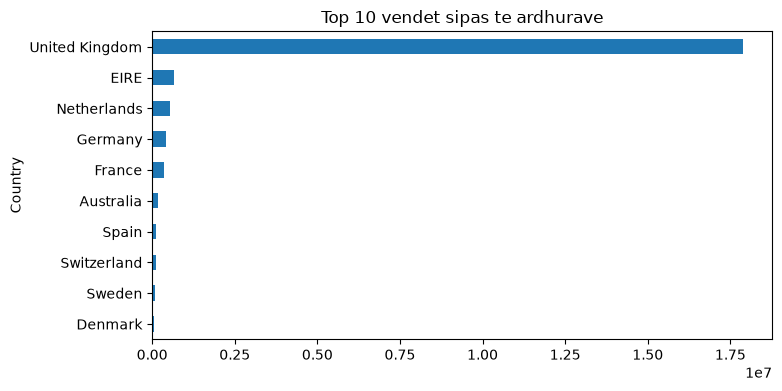

In [9]:
by_country = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
print((by_country.head(10) / by_country.sum() * 100).round(1))

by_country.head(10).sort_values().plot.barh(title="Top 10 vendet sipas te ardhurave", figsize=(8, 4))
plt.show()

In [11]:
cust = (sales.dropna(subset=["Customer ID"])
            .groupby("Customer ID")["Revenue"].sum()
            .sort_values(ascending=False))

n = len(cust)
print("Kliente me ID:", n)
print("Top 10% e klienteve sjellin: ", round(cust.head(int(n * 0.10)).sum() / cust.sum() * 100, 1), "% te te ardhurave")
print("Top 20% e klienteve sjellin: ", round(cust.head(int(n * 0.20)).sum() / cust.sum() * 100, 1), " % te te ardhurave")

Kliente me ID: 5878
Top 10% e klienteve sjellin:  63.9 % te te ardhurave
Top 20% e klienteve sjellin:  77.2  % te te ardhurave


### Përfundimi
- Pas heqjes së kthimeve dhe çmimeve të pavlefshme, mbeten 1041670 rreshta shitjesh (97.6% e të gjithave) për këtë analizë.
- Quantity dhe Price kanë shpërndarje shumë të anuar djathtas (bisht i gjatë), dhe pas logaritmit duken shumë më të barabarta. Për RFM do të përdor logaritëm.
- Të ardhurat për rresht kanë mesatare 20.13% dhe mediane 9.96%, pra pak rreshta të mëdhenj e ngrenë mesataren.
- Produktet kryesore sipas të ardhurave janë  Regency Cakestand 3 Tier, dhe sipas sasisë World War 2 Gliders Asstd Designs. Kam vënë re edhe emra që nuk janë produkte: POSTAGE, MANUAL, DOTCOM POSTAGE.
- Vendi me më shumë të ardhura është United Kingdom, me 85.2% të të ardhurave.
- Top 10% e klientëve sjellin 63.9% të të ardhurave, dhe top 20% sjellin 77.2%.

## EDA Kohore

In [3]:
df["Invoice"] = df["Invoice"].astype(str)
df["Revenue"] = df["Quantity"] * df["Price"]
sales = df[(df["Quantity"] > 0) & (df["Price"] > 0) & (~df["Invoice"].str.startswith("C"))].copy()

sales["Date"] = sales["InvoiceDate"].dt.normalize()
sales["YearMonth"] = sales["InvoiceDate"].dt.to_period("M")
sales["Year"] = sales["InvoiceDate"].dt.year
sales["Month"] = sales["InvoiceDate"].dt.month
sales["DayOfWeek"] = sales["InvoiceDate"].dt.day_name()
sales["Hour"] = sales["InvoiceDate"].dt.hour

print("Rreshta shitjesh: ", len(sales))
print("Data e pare: ", sales["InvoiceDate"].min())
print("Data e fundit: ", sales["InvoiceDate"].max())


Rreshta shitjesh:  1041670
Data e pare:  2009-12-01 07:45:00
Data e fundit:  2011-12-09 12:50:00


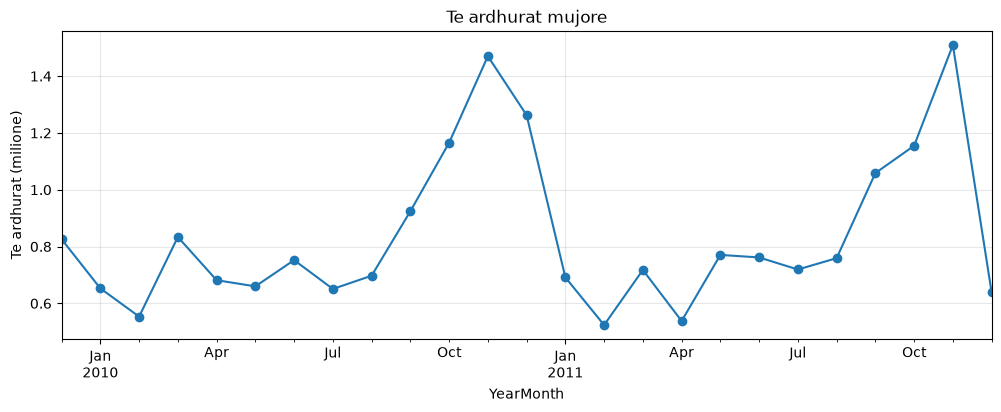

In [4]:
monthly = sales.groupby("YearMonth")["Revenue"].sum() / 1e6

monthly.plot(marker="o", figsize=(12,4))
plt.ylabel("Te ardhurat (milione)")
plt.title("Te ardhurat mujore")
plt.grid(alpha = 0.3)
plt.show()

Year   2009  2010  2011
Month                  
1       NaN  0.65  0.69
2       NaN  0.55  0.52
3       NaN  0.83  0.72
4       NaN  0.68  0.54
5       NaN  0.66  0.77
6       NaN  0.75  0.76
7       NaN  0.65  0.72
8       NaN  0.70  0.76
9       NaN  0.92  1.06
10      NaN  1.17  1.15
11      NaN  1.47  1.51
12     0.83  1.26  0.64


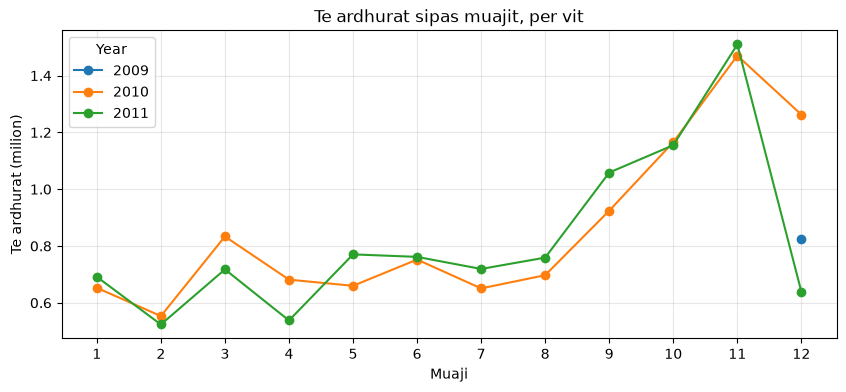

In [5]:
pivot = sales.pivot_table(index="Month", columns="Year", values="Revenue", aggfunc="sum") / 1e6
print(pivot.round(2))

pivot.plot(marker="o", figsize=(10,4))
plt.xticks(range(1,13))
plt.xlabel("Muaji")
plt.ylabel("Te ardhurat (milion)")
plt.title("Te ardhurat sipas muajit, per vit")
plt.grid(alpha=0.3)
plt.show()

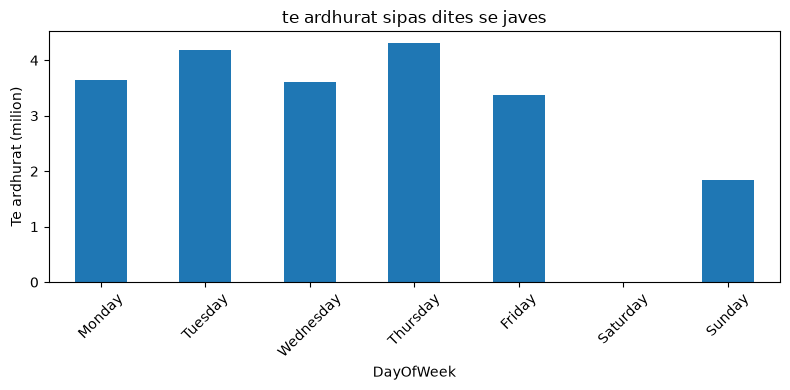

In [6]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
wd = (sales.groupby("DayOfWeek")["Revenue"].sum().reindex(order).fillna(0)) / 1e6

wd.plot.bar(figsize=(8, 4))
plt.ylabel("Te ardhurat (milion)")
plt.title("te ardhurat sipas dites se javes")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

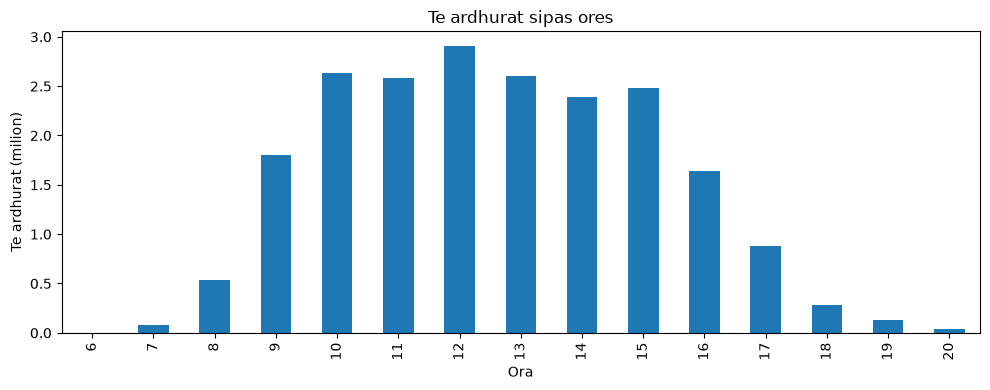

In [7]:
hr = sales.groupby("Hour")["Revenue"].sum() / 1e6

hr.plot.bar(figsize=(10, 4))
plt.xlabel("Ora")
plt.ylabel("Te ardhurat (milion)")
plt.title("Te ardhurat sipas ores")
plt.tight_layout()
plt.show()

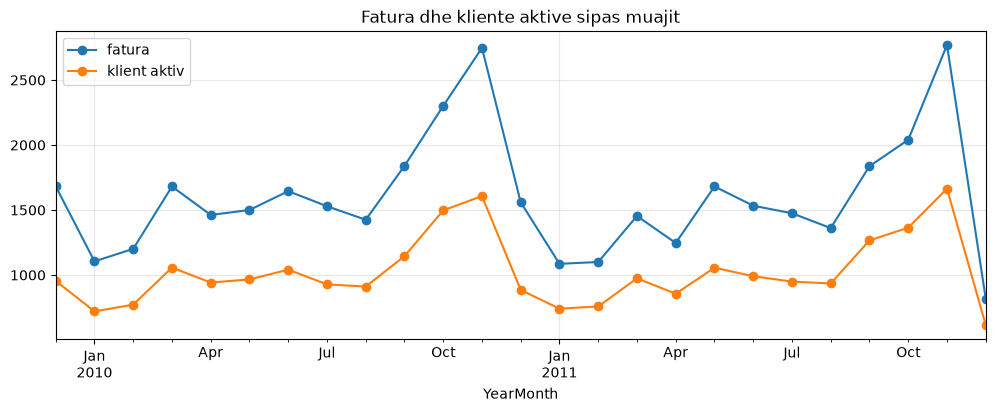

In [8]:
monthly_stats = pd.DataFrame({
    "fatura": sales.groupby("YearMonth")["Invoice"].nunique(),
    "klient aktiv": sales.groupby("YearMonth")["Customer ID"].nunique()
})

monthly_stats.plot(figsize=(12, 4), marker="o")
plt.title("Fatura dhe kliente aktive sipas muajit")
plt.grid(alpha=0.3)
plt.show()

Dite kalendarike:  739
Dite me shitje:  604
Dite pa shitje:  135
Saturday     104
Monday        11
Friday         7
Sunday         6
Thursday       3
Tuesday        2
Wednesday      2
Name: count, dtype: int64
['2009-12-12', '2009-12-19', '2009-12-24', '2009-12-25', '2009-12-26', '2009-12-27', '2009-12-28', '2009-12-29', '2009-12-30', '2009-12-31', '2010-01-01', '2010-01-02', '2010-01-03', '2010-01-09', '2010-01-16', '2010-01-23', '2010-01-30', '2010-12-04', '2010-12-11', '2010-12-18', '2010-12-24', '2010-12-25', '2010-12-26', '2010-12-27', '2010-12-28', '2010-12-29', '2010-12-30', '2010-12-31', '2011-01-01', '2011-01-02', '2011-01-03', '2011-01-08', '2011-01-15', '2011-01-22', '2011-01-29', '2011-12-03']


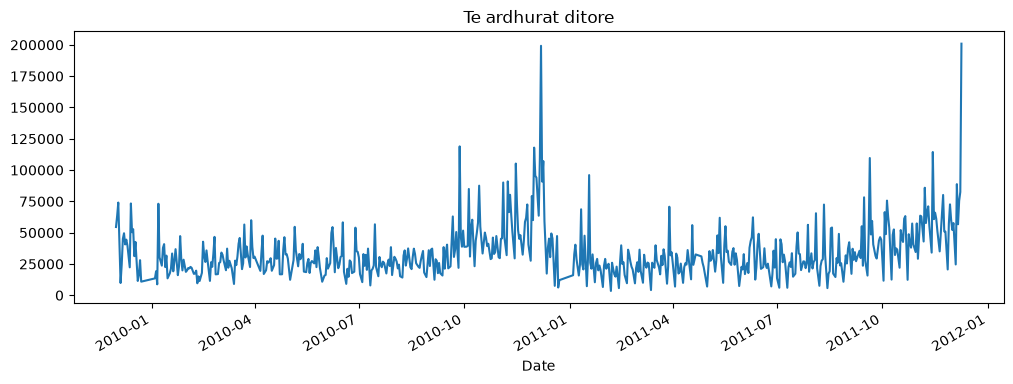

In [9]:
daily = sales.groupby("Date")["Revenue"].sum()
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = full_range.difference(daily.index)

print("Dite kalendarike: ", len(full_range))
print("Dite me shitje: ", len(daily))
print("Dite pa shitje: ", len(missing_days))

md = pd.Series(missing_days)
print(md.dt.day_name().value_counts())
print(md[md.dt.month.isin([12, 1])].dt.strftime("%Y-%m-%d").tolist())

daily.plot(figsize=(12, 4))
plt.title("Te ardhurat ditore")
plt.show()

count   5,878.00
mean        6.29
std        13.01
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       398.00
Name: Invoice, dtype: float64
Klient me vetem 1 porosi:  27.6 %


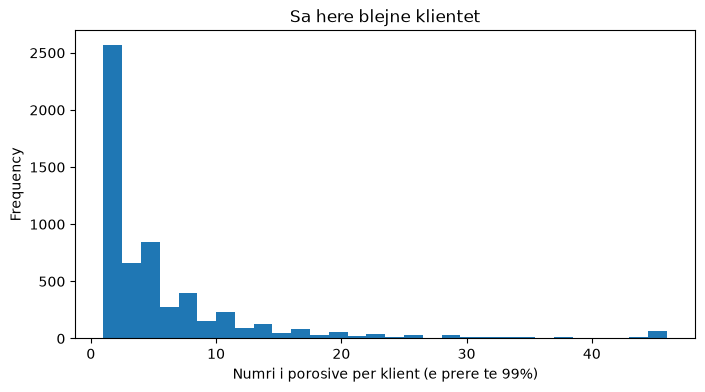

In [10]:
order_per_cust = (sales.dropna(subset=["Customer ID"])
                        .groupby("Customer ID")["Invoice"].nunique())

print(order_per_cust.describe())
print("Klient me vetem 1 porosi: ", round((order_per_cust == 1).mean() * 100, 1), "%")

order_per_cust.clip(upper=order_per_cust.quantile(0.99)).plot.hist(bins=30, figsize=(8, 4))
plt.xlabel("Numri i porosive per klient (e prere te 99%)")
plt.title("Sa here blejne klientet")
plt.show()

# Dita 5: Pastrimi me funksione

In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

from src.data import load_data, clean_data

raw = load_data()
sales, returns = clean_data(raw)
print(sales.shape, returns.shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\Admin\Desktop\online-retail-customer-analytics\notebooks\..\src\data.py:10: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df = pd.read_csv(path, parse_dates=["Invoice"], low_memory=False)


Rreshta fillestare: 1,067,371
Dublikate:                                 hequr:    34335 | mbeten: 1,033,036
Anulime (ndahen te returns)                hequr:    19104 | mbeten: 1,013,932
Quantity <= 0                              hequr:     3393 | mbeten: 1,010,539
Price <= 0                                 hequr:     2626 | mbeten: 1,007,913
Kode te cilat nuk jane produkte            hequr:     4699 | mbeten: 1,003,214
Kodet e hequra (top 10):  {'POST': 1851, 'DOT': 1415, 'M': 846, 'C2': 267, 'ADJUST': 36, 'BANK CHARGES': 34, 'DCGS0058': 30, 'gift_0001_20': 26, 'gift_0001_30': 24, 'DCGSSGIRL': 23}
Rreshta te shitjes pas pastrimit: 1,003,214
(1003214, 8) (19104, 8)


In [4]:
print((sales["Quantity"] > 0).all(), (sales["Price"] > 0).all())
print(sales["Invoice"].str.startswith("C").any())
print(returns["Invoice"].str.startswith("C").all())

True True
False
True


### Vendimet e pastrimit (src/data.py)

| Hapi | Hequr | Mbeten | Arsyeja |
|---|---|---|---|
| Rreshta fillestarë | - | 1,067,371 | |
| Dublikate | 34,335 | 1,033,036 | Rreshta identikë nuk shtojnë informacion |
| Anulime (fatura me C) | 19104 | 1,013,932 | Nuk janë shitje, ndahen te `returns` |
| Quantity <= 0 | 3393 | 1,010,539 | Sasi negative pa anulim (korrigjime), jo shitje |
| Price <= 0 | 2626 | 1,007,913 | Çmime të pavlefshme |
| Kode jo-produkte | 4699 | 1,003,214 | Kodet si POST ose BANK CHARGES nuk janë produkte |

Customer ID që mungon mbahet në `sales`, sepse është i vlefshëm për shitjet totale dhe hiqet vetëm në analizën e klientëve.